In [2]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
import numpy as np

from src.data_loader import load_data

In [3]:
df = load_data("../data/processed/dataset_clean.csv") 

In [4]:
df_regression = df.copy()

count    50000.000000
mean        74.043920
std         15.598327
min         13.000000
25%         64.000000
50%         75.000000
75%         86.000000
max        100.000000
Name: Diabetes_Risk_Score, dtype: float64
Valores distintos: 86


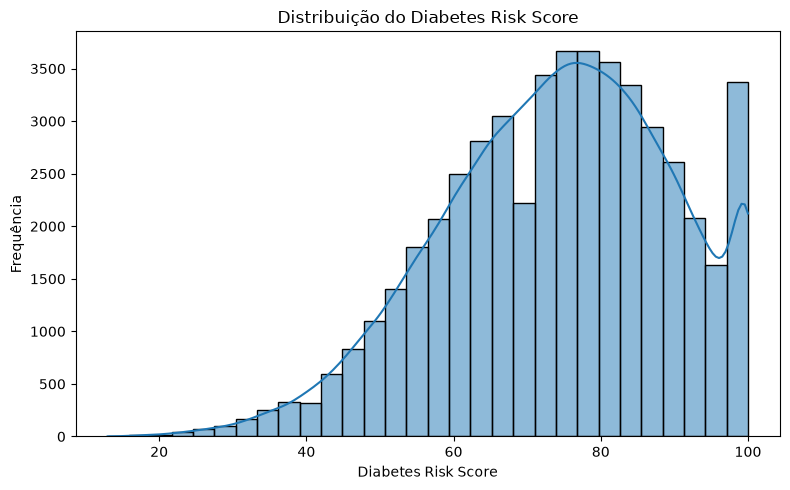

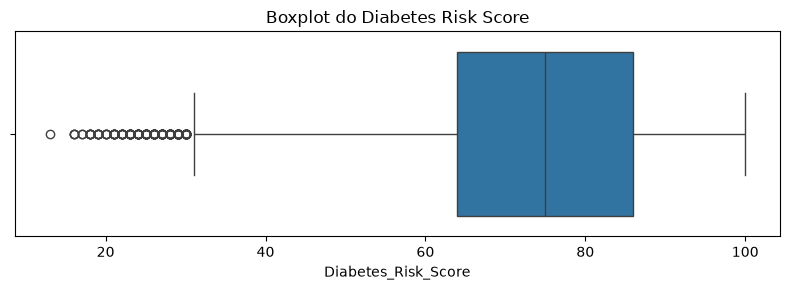

In [5]:
alvo_regressao = "Diabetes_Risk_Score"

# Estatísticas descritivas
print(df_regression[alvo_regressao].describe())

# Quantidade de valores distintos
print(
    "Valores distintos:",
    df_regression[alvo_regressao].nunique()
)

# Histograma
plt.figure(figsize=(8, 5))
sns.histplot(data=df_regression, x=alvo_regressao, bins=30, kde=True)
plt.title("Distribuição do Diabetes Risk Score")
plt.xlabel("Diabetes Risk Score")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

# Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(data=df_regression, x=alvo_regressao)
plt.title("Boxplot do Diabetes Risk Score")
plt.tight_layout()
plt.show()

In [6]:
# Selecionar variáveis numéricas originais
colunas_numericas = (
    df_regression.select_dtypes(include="number")
    .columns
    .drop(
        ["Patient_ID", "Diabetes_Risk_Score"],
        errors="ignore"
    )
)

# Excluir alvos e colunas derivadas da codificação/padronização
colunas_numericas = [
    c for c in colunas_numericas
    if c != "Diabetes_Risk"
    and not c.endswith("_Encoded")
    and not c.endswith("_Scaled")
    and not c.startswith(("Gender_", "Work_Type_"))
]

correlacoes = (
    df_regression[colunas_numericas + ["Diabetes_Risk_Score"]]
    .corr(numeric_only=True)["Diabetes_Risk_Score"]
    .drop("Diabetes_Risk_Score")
    .sort_values(key=abs, ascending=False)
)

print(correlacoes)

Fasting_Blood_Sugar         0.452453
HbA1c                       0.311354
Age                         0.277587
BMI                         0.225605
Weight_kg                   0.199469
Blood_Pressure_Systolic     0.161109
Total_Cholesterol           0.122781
Height_cm                  -0.103532
Blood_Pressure_Diastolic    0.103293
Sleep_Hours                -0.073189
Daily_Water_Intake_L        0.006987
Blood_Glucose               0.005463
Waist_Circumference_cm     -0.004259
Triglycerides              -0.002558
Exercise_Hours_Per_Week    -0.002009
Heart_Rate                 -0.001596
Insulin_Level              -0.001176
LDL                        -0.001043
Daily_Walking_Minutes      -0.000729
HDL                         0.000472
Name: Diabetes_Risk_Score, dtype: float64


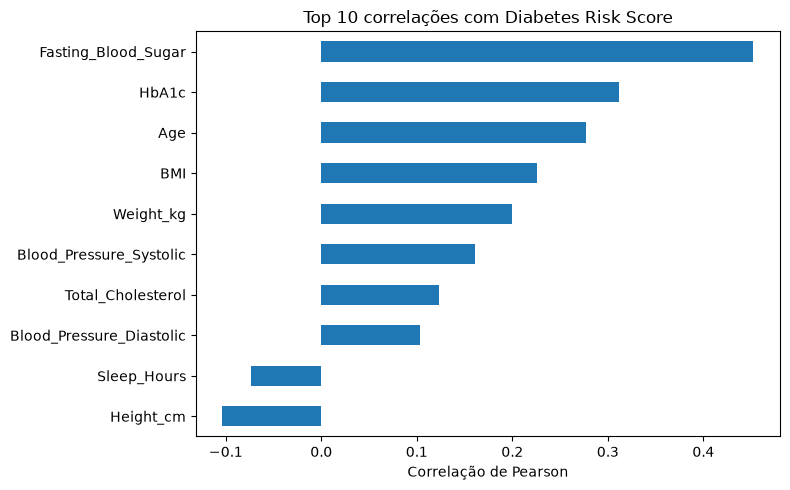

In [7]:
correlacoes_top10 = correlacoes.head(10).sort_values()

correlacoes_top10.plot(
    kind="barh",
    figsize=(8, 5),
    title="Top 10 correlações com Diabetes Risk Score"
)

plt.xlabel("Correlação de Pearson")
plt.tight_layout()
plt.show()

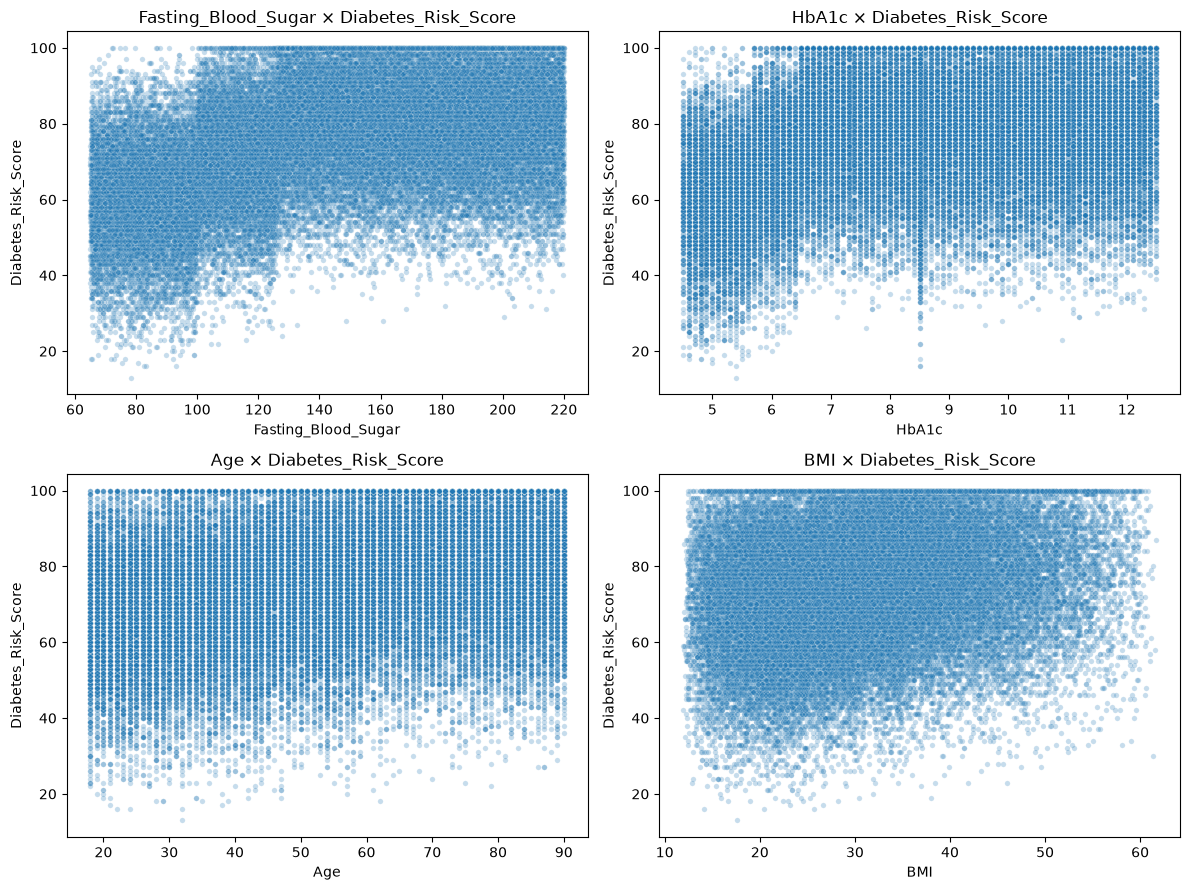

In [8]:
features_top = [
    "Fasting_Blood_Sugar",
    "HbA1c",
    "Age",
    "BMI"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for coluna, ax in zip(features_top, axes.flatten()):
    sns.scatterplot(
        data=df_regression,
        x=coluna,
        y="Diabetes_Risk_Score",
        alpha=0.25,
        s=15,
        ax=ax
    )
    ax.set_title(f"{coluna} × Diabetes_Risk_Score")

plt.tight_layout()
plt.show()

In [9]:
# Relação entre o escore numérico e a classe de risco
print(
    df_regression.groupby("Diabetes_Risk")["Diabetes_Risk_Score"]
    .agg(["count", "min", "max", "mean", "median"])
)

               count  min  max       mean  median
Diabetes_Risk                                    
High           36593   65  100  81.409122    81.0
Low              470   13   34  29.236170    30.0
Moderate       12937   35   64  54.838912    56.0


In [10]:
colunas_investigar = [
    "Diabetes_Risk_Score",
    "Fasting_Blood_Sugar",
    "HbA1c",
    "Diabetes_Risk"
]

print(
    df_regression[colunas_investigar]
    .corr(numeric_only=True)
)

                     Diabetes_Risk_Score  Fasting_Blood_Sugar     HbA1c
Diabetes_Risk_Score             1.000000             0.452453  0.311354
Fasting_Blood_Sugar             0.452453             1.000000 -0.005332
HbA1c                           0.311354            -0.005332  1.000000


In [11]:
for coluna in [
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed"
]:
    print(f"\nDistribuição de {coluna} por classe:")
    print(pd.crosstab(
        df_regression[coluna],
        df_regression["Diabetes_Risk"],
        normalize="index"
    ).round(3))


Distribuição de AI_Health_Recommendation por classe:
Diabetes_Risk                        High  Low  Moderate
AI_Health_Recommendation                                
Annual Diabetes Screening             0.0  1.0       0.0
Balanced Diet                         0.0  1.0       0.0
Begin Diabetes Management Plan        1.0  0.0       0.0
Consult Endocrinologist Immediately   1.0  0.0       0.0
Exercise Regularly                    0.0  1.0       0.0
Healthy Diet Plan                     0.0  0.0       1.0
Immediate Lifestyle Intervention      1.0  0.0       0.0
Increase Physical Activity            0.0  0.0       1.0
Maintain Healthy Lifestyle            0.0  1.0       0.0
Medical Evaluation Required           1.0  0.0       0.0
Monitor Blood Glucose                 0.0  0.0       1.0
Reduce Sugar Intake                   0.0  0.0       1.0
Routine Health Checkup                0.0  1.0       0.0
Strict Blood Sugar Monitoring         1.0  0.0       0.0
Weight Management Program         


Variável: Gender
        count   mean  median    std
Gender                             
Female  16605  74.09    75.0  15.63
Male    16718  74.04    75.0  15.52
Other   16677  74.00    75.0  15.64


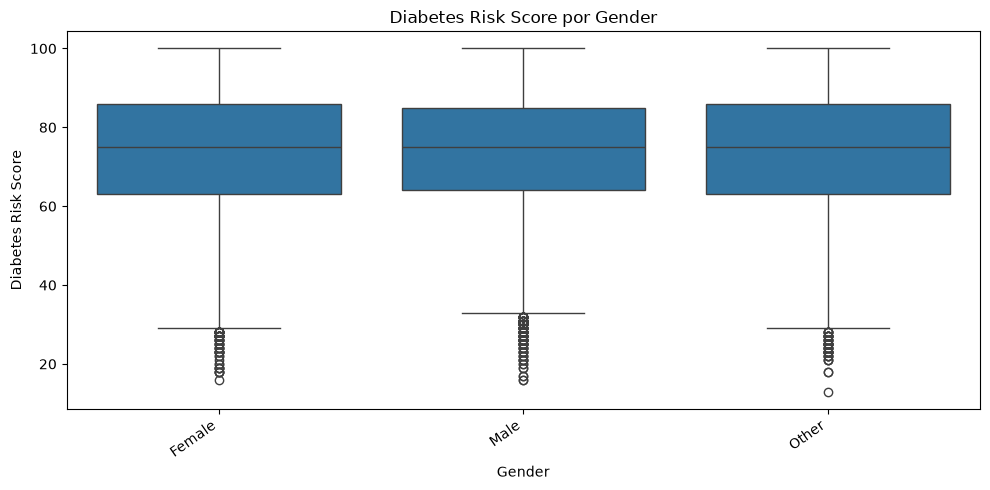


Variável: Country
                count   mean  median    std
Country                                    
Argentina        1952  74.42    76.0  15.27
Australia        1956  73.92    75.0  15.57
Bangladesh       1970  73.95    75.0  15.69
Brazil           1967  73.73    74.0  15.54
Canada           2050  73.78    75.0  15.45
China            2065  74.05    75.0  15.47
Egypt            2010  74.28    75.0  15.58
France           2068  74.22    75.0  15.72
Germany          1999  73.49    74.0  15.72
India            1974  74.14    76.0  15.30
Indonesia        2011  74.09    75.0  15.35
Italy            1989  74.06    75.0  15.86
Japan            1983  73.50    75.0  15.88
Malaysia         2083  74.70    76.0  16.04
Mexico           1999  73.49    75.0  16.00
Nigeria          2023  74.22    75.0  15.54
Pakistan         1959  74.20    76.0  15.68
Russia           2071  74.20    75.0  15.30
Saudi Arabia     1896  74.03    75.0  15.60
South Africa     1996  74.34    75.0  15.72
South Korea  

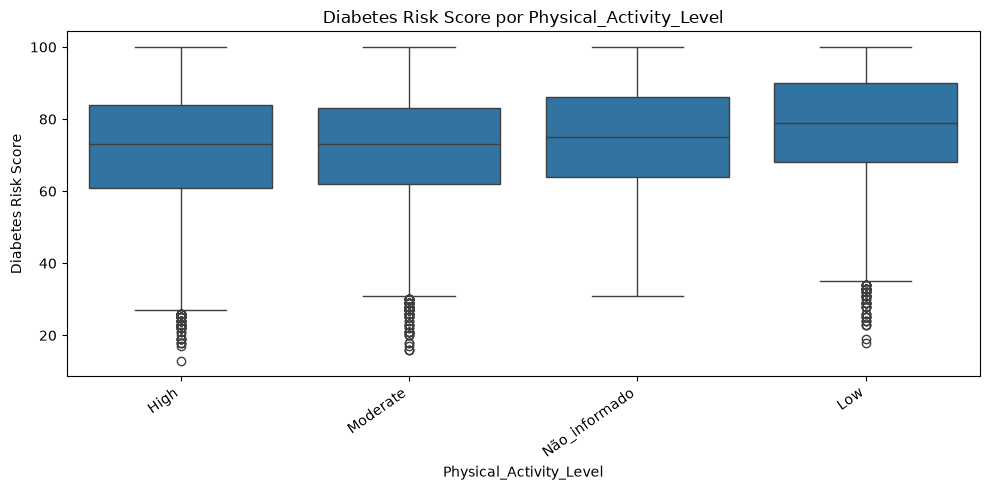


Variável: Diet_Quality
              count   mean  median    std
Diet_Quality                             
Average       16644  72.24    73.0  15.56
Healthy       16882  72.02    73.0  15.59
Poor          16474  77.94    79.0  14.91


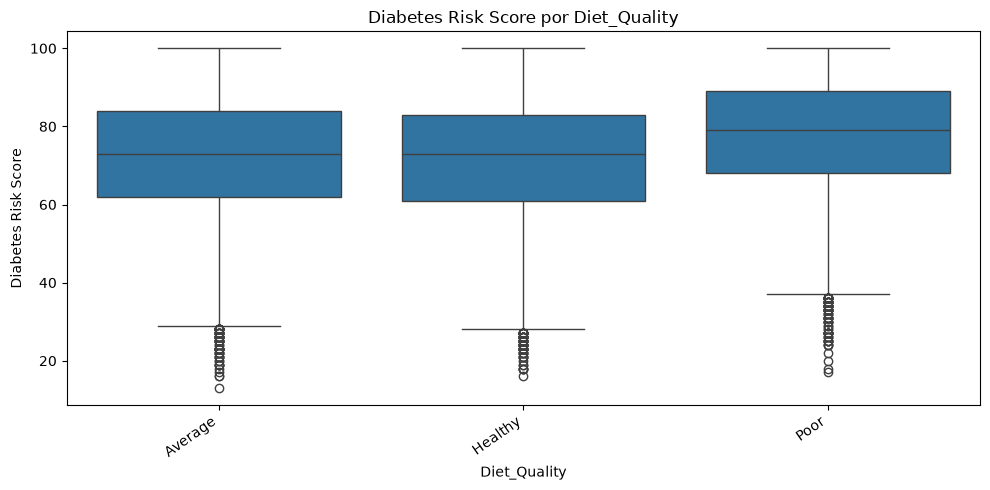


Variável: Sugar_Intake_Level
                    count   mean  median    std
Sugar_Intake_Level                             
High                16438  74.05    75.0  15.65
Low                 16864  74.04    75.0  15.54
Moderate            16698  74.04    75.0  15.60


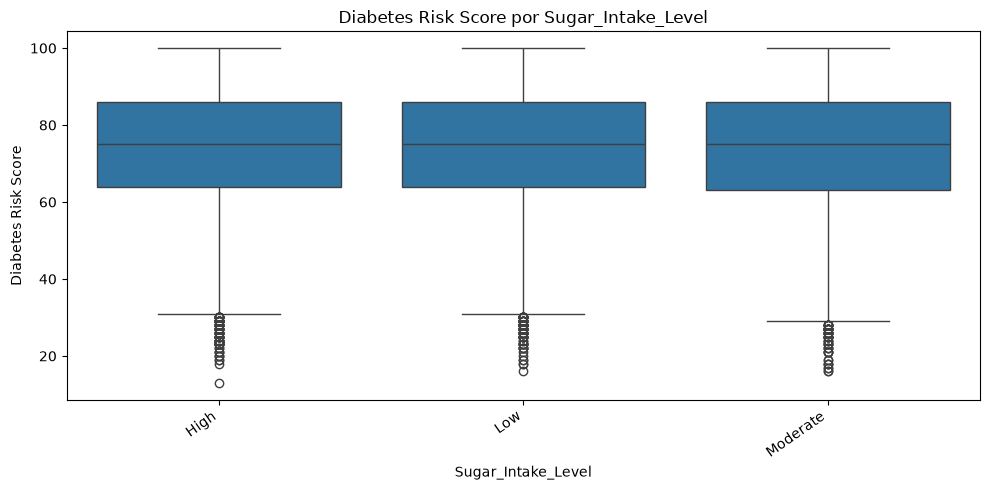


Variável: Stress_Level
              count   mean  median    std
Stress_Level                             
High          16674  77.17    78.0  15.10
Low           16725  72.31    73.0  15.70
Moderate      16601  72.64    74.0  15.51


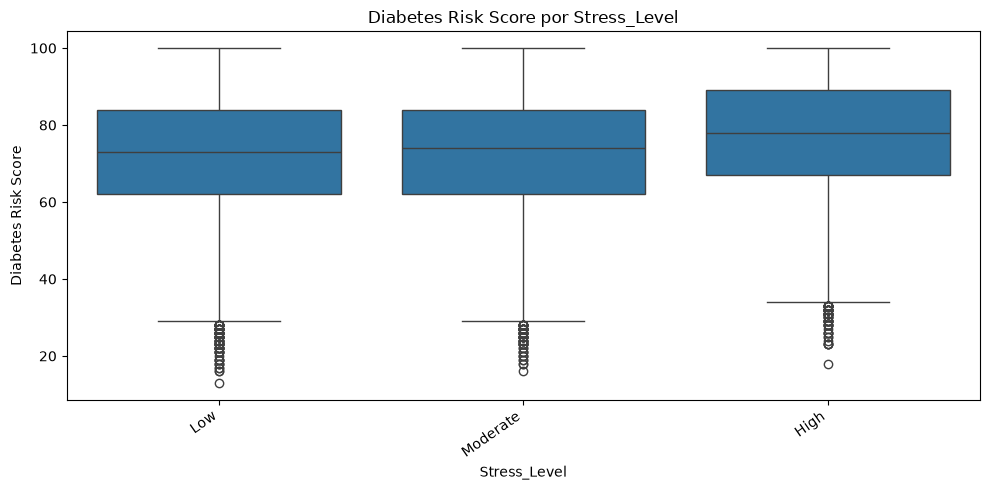


Variável: Smoking_Status
                count   mean  median    std
Smoking_Status                             
Current         16693  77.29    79.0  15.17
Former          16729  72.53    73.0  15.54
Never           16578  72.30    73.0  15.58


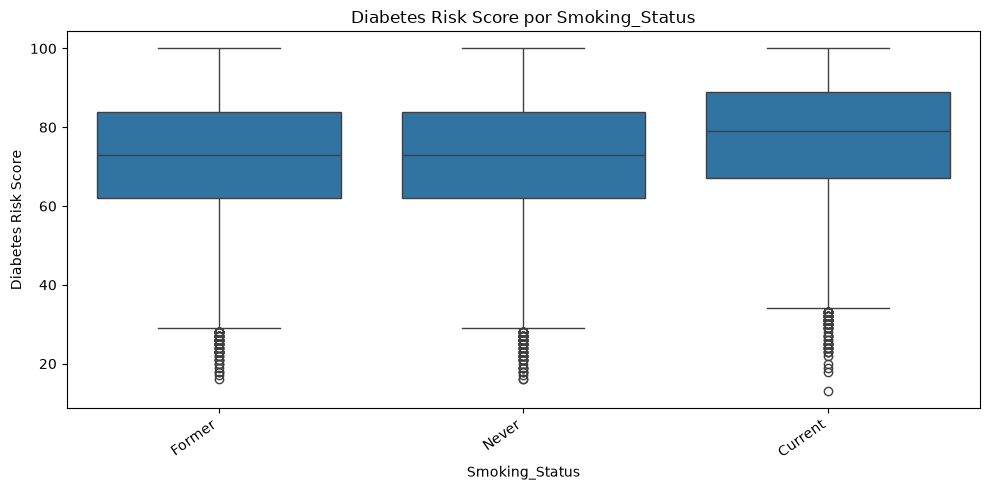


Variável: Alcohol_Consumption
                     count   mean  median    std
Alcohol_Consumption                             
Frequently           16606  76.61    78.0  15.30
Never                16712  72.61    74.0  15.62
Occasionally         16682  72.93    74.0  15.56


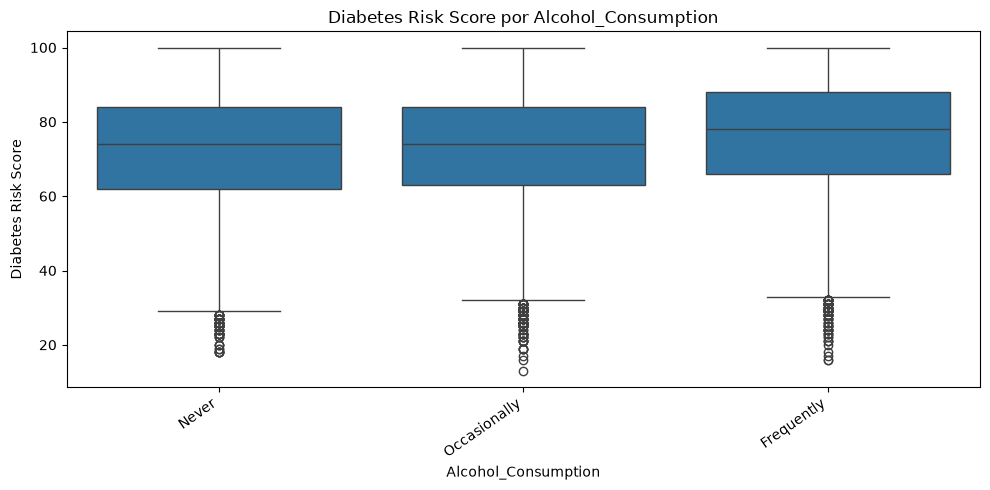


Variável: Family_History_Diabetes
                         count   mean  median    std
Family_History_Diabetes                             
No                       25076  69.26    70.0  15.17
Yes                      24924  78.86    80.0  14.51


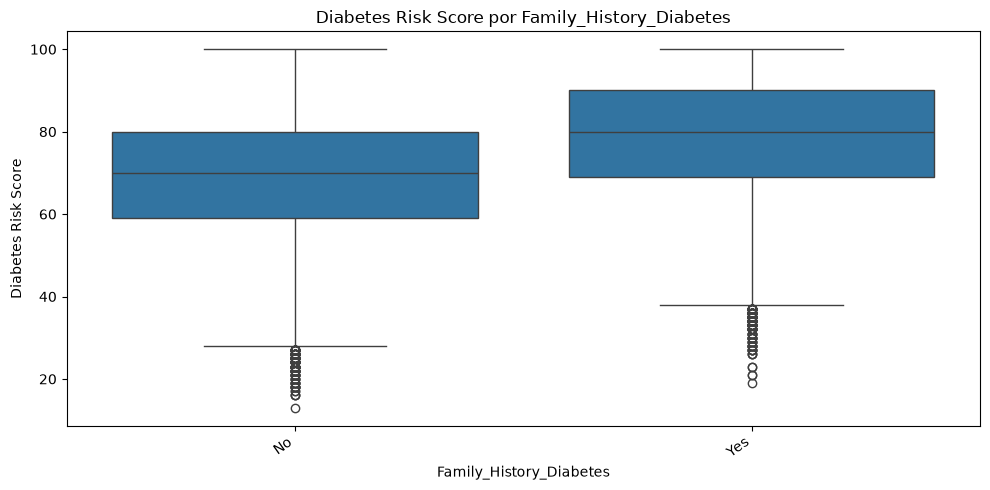


Variável: Hypertension
              count   mean  median    std
Hypertension                             
No            24800  71.06    72.0  15.58
Yes           25200  76.98    78.0  15.05


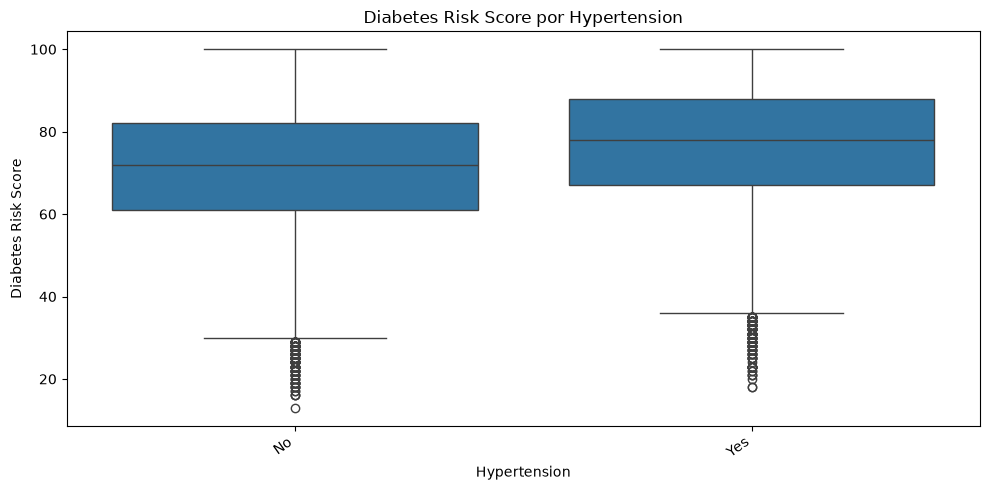


Variável: Heart_Disease
               count   mean  median    std
Heart_Disease                             
No             25288  71.69    73.0  15.65
Yes            24712  76.46    78.0  15.17


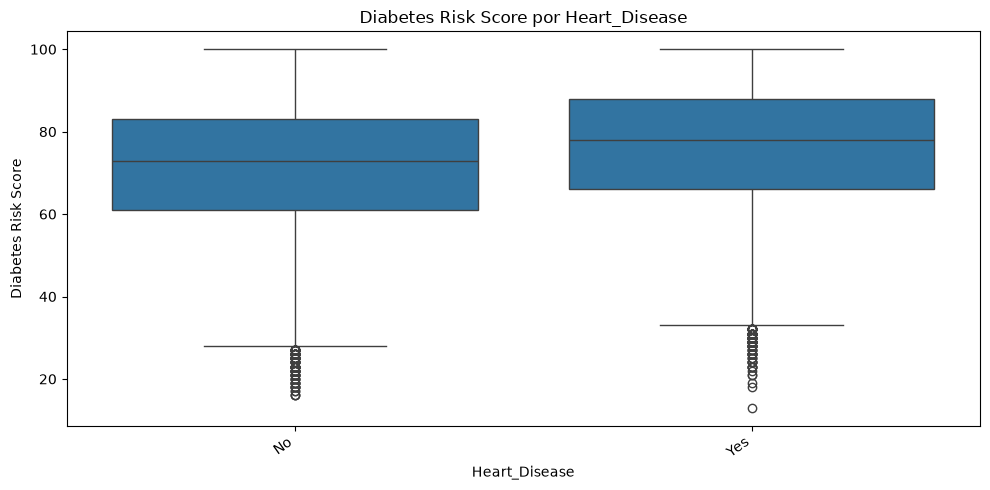


Variável: Fatty_Liver
             count   mean  median    std
Fatty_Liver                             
No           25155  72.11    73.0  15.61
Yes          24845  76.01    77.0  15.34


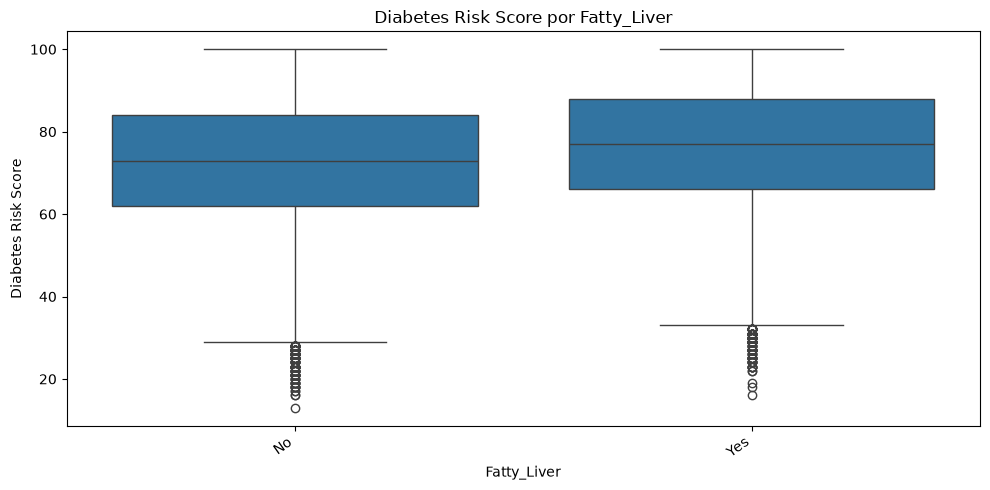


Variável: PCOS
      count   mean  median    std
PCOS                             
No    25071  71.61    73.0  15.69
Yes   24929  76.49    78.0  15.12


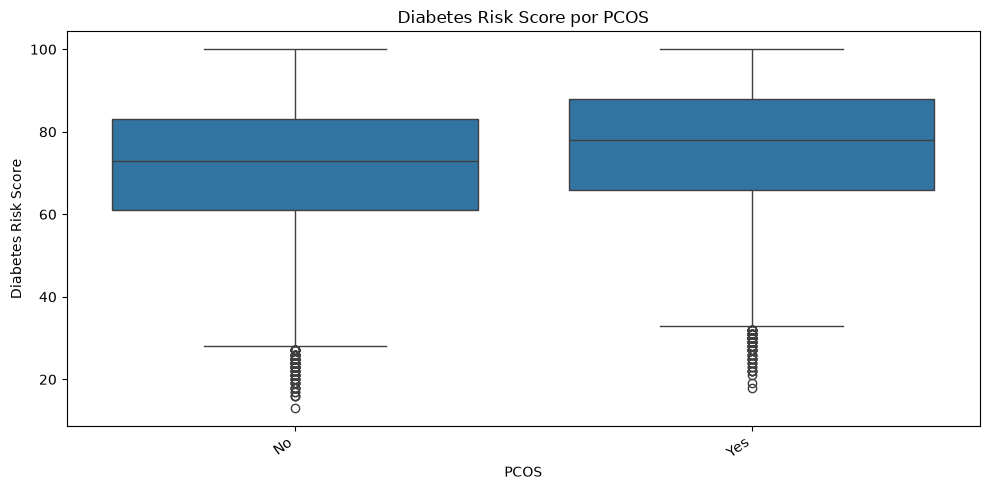


Variável: Medication_Adherence
                      count   mean  median    std
Medication_Adherence                             
Average               16351  72.70    74.0  15.63
Good                  16361  72.86    74.0  15.61
Não_informado          1000  72.70    73.0  15.23
Poor                  16288  76.67    78.0  15.25


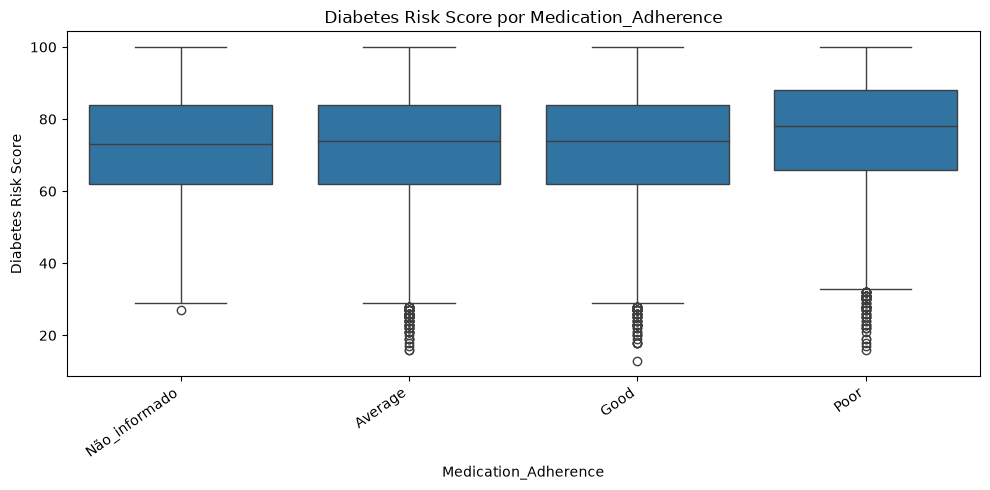


Variável: Work_Type
            count   mean  median    std
Work_Type                              
Business    10167  73.96    75.0  15.76
Government   9987  74.05    75.0  15.36
Private     10063  74.08    75.0  15.69
Retired      9819  74.02    75.0  15.64
Student      9964  74.11    75.0  15.54


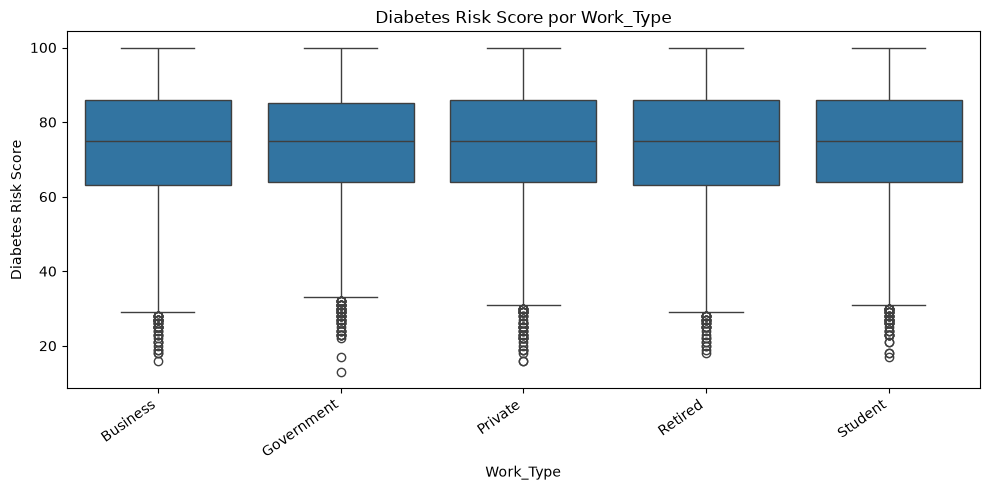


Variável: Residence_Type
                count   mean  median   std
Residence_Type                            
Rural           24871  74.14    75.0  15.5
Urban           25129  73.94    75.0  15.7


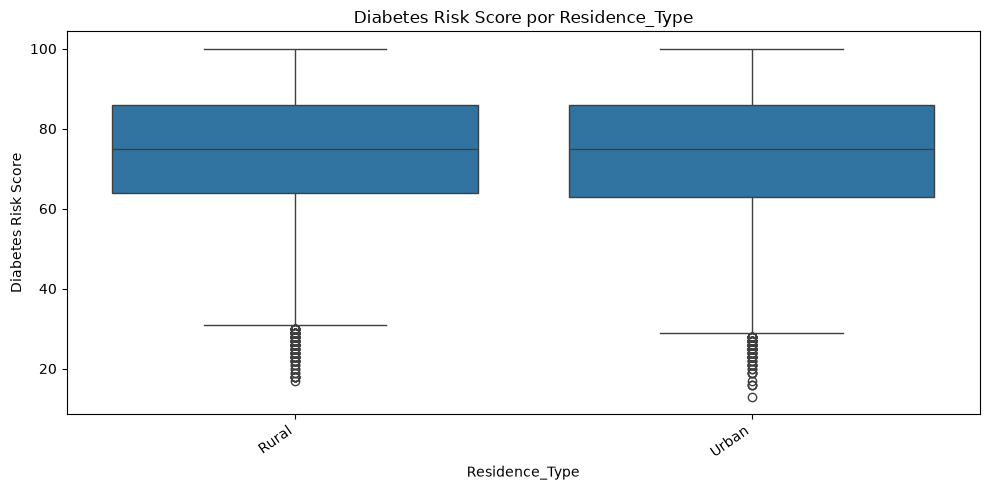


Variável: AI_Health_Recommendation
                                     count   mean  median    std
AI_Health_Recommendation                                        
Annual Diabetes Screening               86  29.00    30.0   4.55
Balanced Diet                          100  29.46    30.0   3.82
Begin Diabetes Management Plan        7192  81.39    81.0  10.18
Consult Endocrinologist Immediately   7271  81.54    81.0  10.15
Exercise Regularly                     113  29.30    31.0   4.20
Healthy Diet Plan                     2560  54.92    57.0   7.28
Immediate Lifestyle Intervention      7419  81.47    81.0  10.19
Increase Physical Activity            2564  54.62    56.0   7.30
Maintain Healthy Lifestyle              80  28.80    29.0   4.10
Medical Evaluation Required           7230  81.25    80.0  10.10
Monitor Blood Glucose                 2582  55.00    56.0   7.14
Reduce Sugar Intake                   2615  54.84    56.0   7.25
Routine Health Checkup                  91  29.52    3

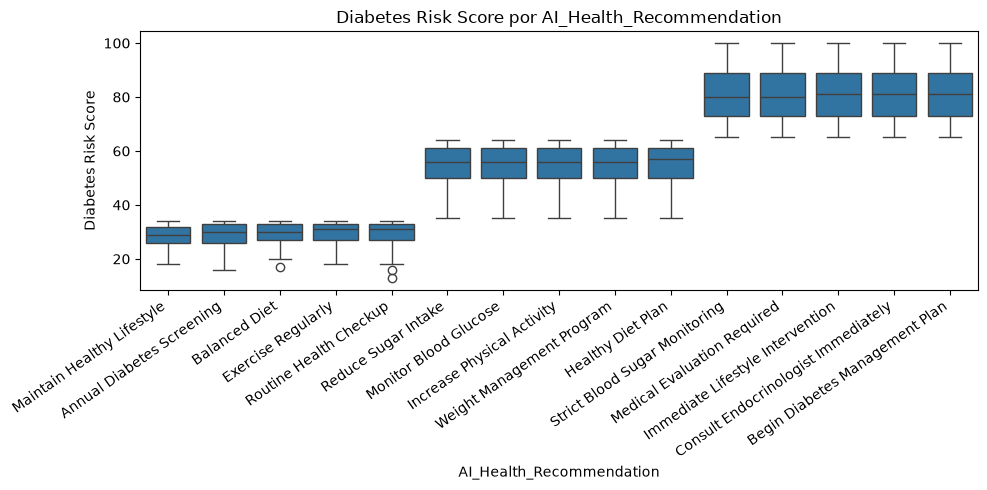


Variável: Doctor_Consultation_Needed
                            count   mean  median    std
Doctor_Consultation_Needed                             
No                           3574  51.72    55.0  10.73
Yes                         46426  75.76    76.0  14.55


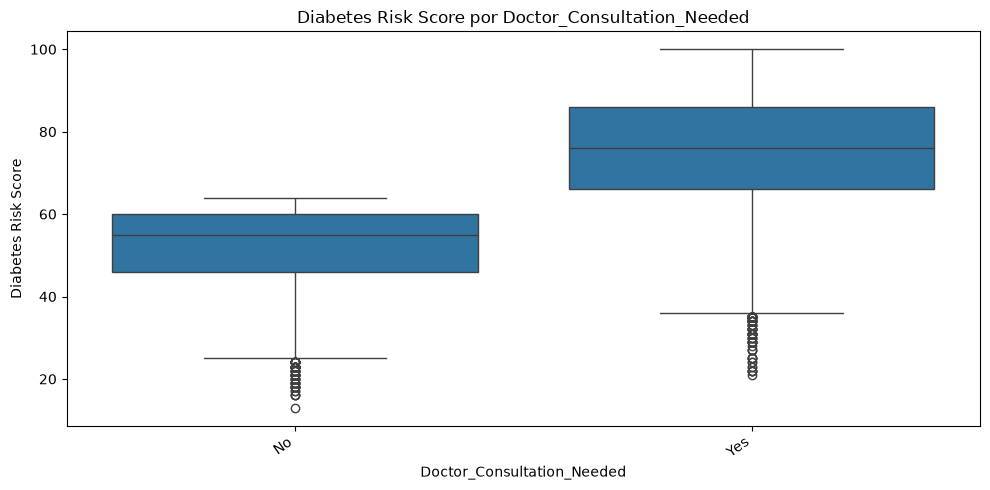


Variável: Diabetes_Risk
               count   mean  median    std
Diabetes_Risk                             
High           36593  81.41    81.0  10.16
Low              470  29.24    30.0   4.30
Moderate       12937  54.84    56.0   7.25


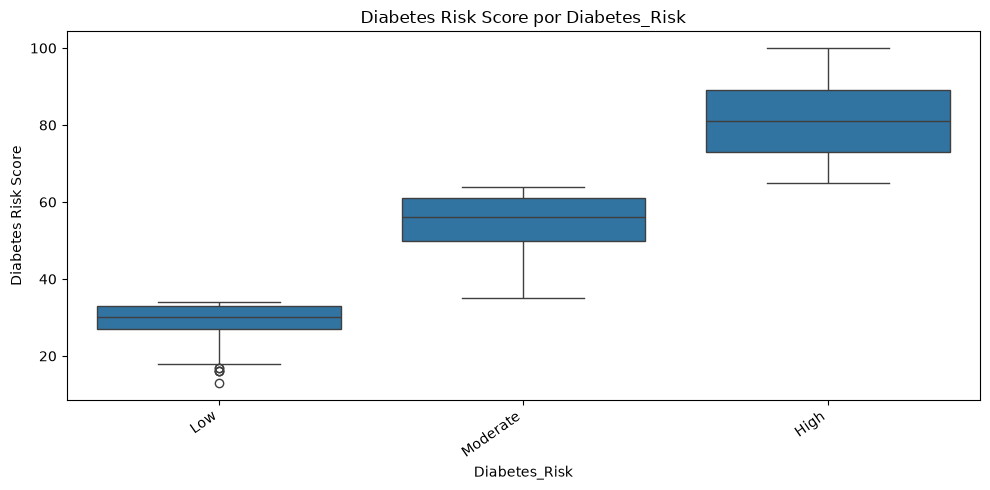


Variável: BMI_CATEGORY
              count   mean  median    std
BMI_CATEGORY                             
Normal        10602  69.38    70.0  15.45
Obese         24999  77.67    79.0  14.88
Overweight     8639  72.53    73.0  15.20
Underweight    5760  69.17    70.0  15.53


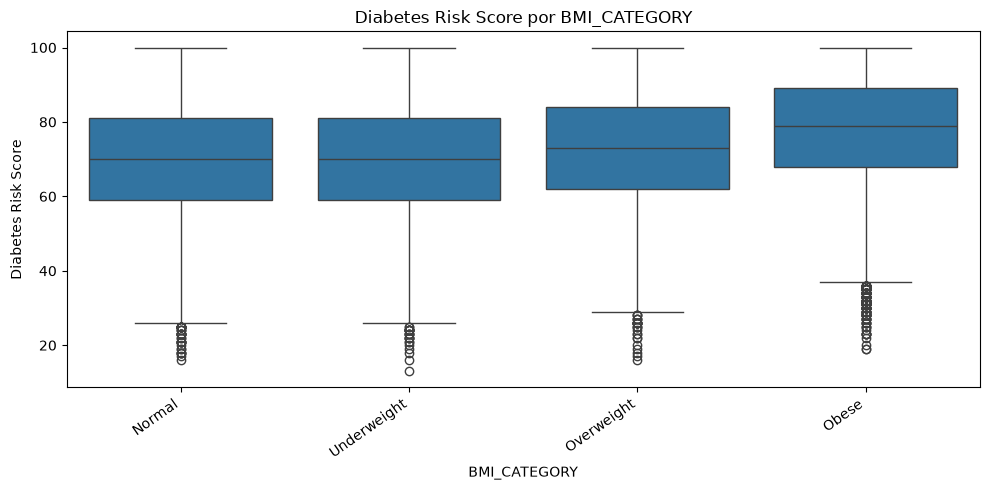

In [12]:
colunas_categoricas = [
    "Gender",
    "Country",
    "Physical_Activity_Level",
    "Diet_Quality",
    "Sugar_Intake_Level",
    "Stress_Level",
    "Smoking_Status",
    "Alcohol_Consumption",
    "Family_History_Diabetes",
    "Hypertension",
    "Heart_Disease",
    "Fatty_Liver",
    "PCOS",
    "Medication_Adherence",
    "Work_Type",
    "Residence_Type",
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed",
    "Diabetes_Risk",
    "BMI_CATEGORY"
]

for coluna in colunas_categoricas:

    print(f"\n{'=' * 60}")
    print(f"Variável: {coluna}")

    estatisticas = (
        df_regression
        .groupby(coluna, dropna=False, observed=True)
        ["Diabetes_Risk_Score"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

    print(estatisticas)

    # Country pode ter muitas categorias.
    # Primeiro, exibimos sua tabela; os demais gráficos
    # ficam mais fáceis de interpretar.
    if coluna == "Country":
        continue

    plt.figure(figsize=(10, 5))

    ordem = (
        df_regression
        .groupby(coluna, dropna=False, observed=True)
        ["Diabetes_Risk_Score"]
        .median()
        .sort_values()
        .index
    )

    sns.boxplot(
        data=df_regression,
        x=coluna,
        y="Diabetes_Risk_Score",
        order=ordem
    )

    plt.title(f"Diabetes Risk Score por {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Diabetes Risk Score")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

In [13]:
df_regression.groupby("BMI_CATEGORY", observed=True)["BMI"].agg(
    ["count", "min", "max", "mean", "median", "std"]
).round(2)

,count,min,max,mean,median,std
BMI_CATEGORY,,,,,,
Normal,10602,18.6,25.0,21.87,21.9,1.85
Obese,24999,30.1,61.7,39.35,37.8,6.97
Overweight,8639,25.1,30.0,27.54,27.5,1.45
Underweight,5760,11.9,18.5,16.10,16.3,1.63


In [14]:
pd.crosstab(
    pd.cut(df_regression["BMI"], bins=10),
    df_regression["BMI_CATEGORY"]
)

BMI_CATEGORY,Normal,Obese,Overweight,Underweight
BMI,,,,
"(11.85, 16.88]",0,0,0,3538
"(16.88, 21.86]",5231,0,0,2222
"(21.86, 26.84]",5371,0,3117,0
"(26.84, 31.82]",0,3120,5522,0
"(31.82, 36.8]",0,8177,0,0
"(36.8, 41.78]",0,5647,0,0
"(41.78, 46.76]",0,3891,0,0
"(46.76, 51.74]",0,2479,0,0
"(51.74, 56.72]",0,1282,0,0


In [15]:
# Para cada valor de BMI, contar quantas categorias diferentes aparecem
categorias_por_bmi = (
    df_regression.groupby("BMI", dropna=False)["BMI_CATEGORY"]
    .nunique()
)

print("Proporção de valores de BMI associados a uma única categoria:")
print((categorias_por_bmi.eq(1).mean() * 100).round(2), "%")

Proporção de valores de BMI associados a uma única categoria:
100.0 %


In [16]:
features_categoricas = [
    "Gender",
    "Physical_Activity_Level",
    "Diet_Quality",
    "Sugar_Intake_Level",
    "Stress_Level",
    "Smoking_Status",
    "Alcohol_Consumption",
    "Family_History_Diabetes",
    "Hypertension",
    "Heart_Disease",
    "Fatty_Liver",
    "PCOS",
    "Medication_Adherence"
]

resultados = []

for coluna in features_categoricas:
    grupos = [
        grupo["Diabetes_Risk_Score"].dropna().to_numpy()
        for _, grupo in df_regression.groupby(
            coluna, observed=True, dropna=False
        )
    ]

    grupos = [grupo for grupo in grupos if len(grupo) > 0]

    estatistica, p_valor = kruskal(*grupos)

    n = sum(len(grupo) for grupo in grupos)
    k = len(grupos)

    # Estimativa do tamanho do efeito: epsilon quadrado
    epsilon2 = max(0, (estatistica - k + 1) / (n - k))

    resultados.append({
        "Feature": coluna,
        "Grupos": k,
        "Estatistica_H": estatistica,
        "p_valor": p_valor,
        "Epsilon_quadrado": epsilon2
    })

resultado_testes = pd.DataFrame(resultados)

# Correção para múltiplos testes (Benjamini-Hochberg)
resultado_testes["p_ajustado"] = multipletests(
    resultado_testes["p_valor"],
    method="fdr_bh"
)[1]

resultado_testes = resultado_testes.sort_values(
    "p_ajustado"
)

print(resultado_testes.round(6).to_string(index=False))

                Feature  Grupos  Estatistica_H  p_valor  Epsilon_quadrado  p_ajustado
Physical_Activity_Level       4    1486.804310 0.000000          0.029678    0.000000
           Diet_Quality       3    1513.452886 0.000000          0.030231    0.000000
Family_History_Diabetes       2    4717.956378 0.000000          0.094343    0.000000
           Hypertension       2    1758.973001 0.000000          0.035161    0.000000
                   PCOS       2    1188.200689 0.000000          0.023745    0.000000
          Heart_Disease       2    1151.706016 0.000000          0.023015    0.000000
         Smoking_Status       3    1088.736701 0.000000          0.021736    0.000000
           Stress_Level       3    1002.656669 0.000000          0.020014    0.000000
            Fatty_Liver       2     762.748658 0.000000          0.015236    0.000000
   Medication_Adherence       4     671.731792 0.000000          0.013376    0.000000
    Alcohol_Consumption       3     665.332224 0.00000

In [17]:
df_regression.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 85 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Patient_ID                          50000 non-null  int64  
 1   Age                                 50000 non-null  float64
 2   Gender                              50000 non-null  str    
 3   Country                             50000 non-null  str    
 4   Height_cm                           50000 non-null  float64
 5   Weight_kg                           50000 non-null  float64
 6   BMI                                 50000 non-null  float64
 7   Waist_Circumference_cm              50000 non-null  float64
 8   Blood_Glucose                       50000 non-null  float64
 9   HbA1c                               50000 non-null  float64
 10  Fasting_Blood_Sugar                 50000 non-null  float64
 11  Insulin_Level                       50000 non-null  

In [18]:
# Features selecionadas
features_regressao = [
    "Fasting_Blood_Sugar_Scaled",
    "HbA1c_Scaled",
    "Age_Scaled",
    "BMI_Scaled",
    "Family_History_Diabetes_Encoded",
    "Hypertension_Encoded",
    "Diet_Quality_Encoded",
    "Physical_Activity_Level_Encoded"
]

# Target
target = "Diabetes_Risk_Score"

# Selecionar somente as features e o target
df_regression = df[features_regressao + [target]].copy()

# Conferir o resultado
display(df_regression.head())
print("Dimensões:", df_regression.shape)
print("\nTipos de dados:")

,Fasting_Blood_Sugar_Scaled,HbA1c_Scaled,Age_Scaled,BMI_Scaled,Family_History_Diabetes_Encoded,Hypertension_Encoded,Diet_Quality_Encoded,Physical_Activity_Level_Encoded,Diabetes_Risk_Score
0,0.154264,0.842947,-1.040320,-1.081056,1,0,2,1,60
1,1.268823,1.239842,-0.564688,1.455390,1,0,2,2,99
2,1.723151,-0.965130,1.670782,0.677935,1,0,1,2,80
3,1.680627,-0.480037,1.575655,-0.449374,1,1,1,2,82
4,0.243786,1.548538,-1.278136,1.018072,0,1,0,1,93


Dimensões: (50000, 9)

Tipos de dados:


In [20]:
df_regression.to_csv(
    "../data/processed/dataset_regression.csv",
    index=False,
    encoding="utf-8"
)

print("Dataset de regressão salvo com sucesso!")

Dataset de regressão salvo com sucesso!
